# MNIST: Classical ML vs MLP vs CNN
**Assignment 1 - training three models on MNIST + interactive drawing app**

This notebook is the complete, executable record of the experiments: data loading and preprocessing, hyper-parameter
search, evaluation, comparison, model selection, model saving and smoke tests. Everything below was actually run
(outputs are stored in the notebook); nothing is typed in by hand.

**The three models (exactly three, as required)**

| # | Category | Algorithm |
|---|----------|-----------|
| 1 | Classical machine learning | Support Vector Machine with RBF kernel (scikit-learn `SVC`) |
| 2 | Neural network | Multi-layer perceptron, fully connected layers only (PyTorch) |
| 3 | Deep-learning computer vision | Simple CNN: 2 x (Conv-ReLU-MaxPool) + 2 fully connected layers (PyTorch) |

**Notebook map:** 1 Setup - 2 Data - 3 Preprocessing - 4 Evaluation plan - 5 SVM - 6 MLP - 7 CNN - 8 Saving -
9 Smoke tests.

**Model comparison, comparison charts and the final model selection are in the companion notebook `model_comparison_and_selection.ipynb`**, which loads the three saved models and the results stored in `../artifacts` by this notebook.

## 1. Setup and reproducibility

In [1]:
import sys
try:
    import torch, sklearn, seaborn, flask  # packages installed only in the project's .venv
except ModuleNotFoundError as e:
    raise RuntimeError(f"Wrong kernel: '{sys.executable}' is missing '{e.name}'. In VS Code click 'Select Kernel' (top right) -> "
                       "'Python Environments' -> choose the interpreter  <project>/.venv/Scripts/python.exe, then run again.") from None
print("kernel python:", sys.executable)
import sys, time, json, platform, warnings
from pathlib import Path
sys.path.insert(0, str(Path("..").resolve() / "src"))      # reusable helpers live in ../src
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import sklearn, torch, joblib
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix, classification_report

from data_preprocessing import *
from model_utils import *

SEED = 42
set_seed(SEED)
ARTIFACTS = Path("..") / "artifacts"; ARTIFACTS.mkdir(exist_ok=True)
MODELS = Path("..") / "models";       MODELS.mkdir(exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")

print("python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__, "| torch", torch.__version__)
print("device:", DEVICE, "| torch threads:", torch.get_num_threads(), "| seed:", SEED)

kernel python: E:\trainingproject 1\.venv\Scripts\python.exe


python 3.11.15 | numpy 2.4.6 | pandas 3.0.6 | scikit-learn 1.9.1 | torch 2.14.1+cu130
device: cuda | torch threads: 6 | seed: 42


## 2. Loading and inspecting MNIST
MNIST = 70,000 grey-scale images of handwritten digits 0-9: 60,000 for training and 10,000 for the official test set.
It is downloaded automatically to `../data` the first time (via `torchvision.datasets.MNIST`).

0.3%

0.7%

1.0%

1.3%

1.7%

...

100.0%

100.0%

train images: (60000, 28, 28) uint8 | labels: (60000,) int64
test  images: (10000, 28, 28) uint8 | labels: (10000,)
pixel range : 0 - 255 | mean 33.3


missing values: 0


,0,1,2,3,4,5,6,7,8,9
train,5923,6742,5958,6131,5842,5421,5918,6265,5851,5949
test,980,1135,1032,1010,982,892,958,1028,974,1009


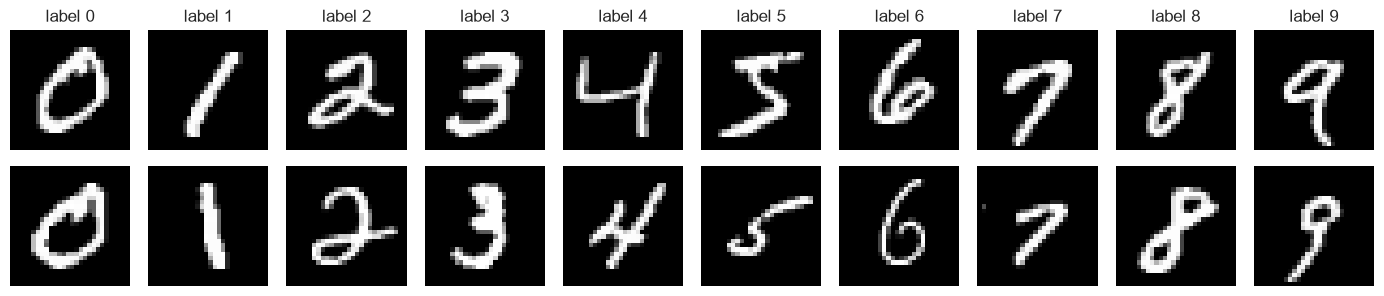

In [2]:
x_train_raw, y_train_raw, x_test_raw, y_test_raw = load_raw_mnist()
print("train images:", x_train_raw.shape, x_train_raw.dtype, "| labels:", y_train_raw.shape, y_train_raw.dtype)
print("test  images:", x_test_raw.shape,  x_test_raw.dtype,  "| labels:", y_test_raw.shape)
print("pixel range :", x_train_raw.min(), "-", x_train_raw.max(), "| mean %.1f" % x_train_raw.mean())
print("missing values:", int(np.isnan(x_train_raw.astype(float)).sum()))

counts = pd.DataFrame({"train": np.bincount(y_train_raw), "test": np.bincount(y_test_raw)})
display(counts.T)

fig, axes = plt.subplots(2, 10, figsize=(14, 3.2))
for d in range(10):
    for r in range(2):
        axes[r, d].imshow(x_train_raw[np.where(y_train_raw == d)[0][r]], cmap="gray"); axes[r, d].axis("off")
        if r == 0: axes[r, d].set_title(f"label {d}")
plt.tight_layout(); plt.show()

**Findings:** each image is a 28x28 array of `uint8` values (0 = black background, 255 = white stroke), labels are integers
0-9, there are no missing values, and the ten classes are roughly balanced (about 9-11 % each). The task is therefore a balanced
10-class image-classification problem, for which accuracy is a meaningful headline metric.

## 3. Preprocessing
Every step, and why it is done (the same contract is used by the app in `src/inference.py`):

| Step | What | Why |
|------|------|-----|
| 1. Scale pixels | `uint8` 0-255 -> `float32` 0.0-1.0 (divide by 255) | Gradient-based networks train much faster and more stably with small inputs; the RBF-SVM kernel `exp(-gamma*||x-x'||^2)` also needs features on a common small scale so one `gamma` works. |
| 2. Reshape for model type | SVM and MLP: flatten to a 784-vector. CNN: keep 28x28 and add a channel axis -> `(1, 28, 28)` | SVM/MLP take a feature vector; the CNN needs the 2-D spatial layout to apply convolutions. |
| 3. Train / validation split | 54,000 train + 6,000 validation, **stratified**, fixed seed | Hyper-parameters are chosen on the validation set so that the official **test set stays untouched** until the final evaluation (no tuning on test data). |
| 4. Labels | kept as integers 0-9 | `CrossEntropyLoss` (PyTorch) and `SVC` both take integer class labels; no one-hot encoding is required. |
| 5. (App only) canvas -> MNIST format | crop to the digit's bounding box, fit into 20x20 keeping aspect ratio, centre by centre of mass in 28x28, white digit on black | The original MNIST digits were prepared this way. A hand-drawn digit that fills the whole 280x280 canvas would otherwise look very different from the training data. |

No data augmentation and no mean/std standardisation are used (kept simple; [0,1] scaling is sufficient for MNIST).

In [3]:
x_train_all = scale_pixels(x_train_raw)     # (60000, 28, 28) float32 in [0, 1]
x_test      = scale_pixels(x_test_raw)      # (10000, 28, 28)
y_test      = y_test_raw

x_tr, x_val, y_tr, y_val = train_val_split(x_train_all, y_train_raw, val_size=6000, seed=SEED)

# flat (SVM, MLP) and image (CNN) views of the same data
X = {"flat": dict(train=flatten(x_tr), val=flatten(x_val), test=flatten(x_test)),
     "img":  dict(train=add_channel(x_tr), val=add_channel(x_val), test=add_channel(x_test))}

print("flat shapes:", {k: v.shape for k, v in X["flat"].items()})
print("img  shapes:", {k: v.shape for k, v in X["img"].items()})
print("value range after scaling: %.1f - %.1f, dtype %s" % (x_tr.min(), x_tr.max(), x_tr.dtype))
split_table = pd.DataFrame({"train": np.bincount(y_tr), "val": np.bincount(y_val), "test": np.bincount(y_test)})
display(split_table.T)

# fixed random 10k subsample of the training split, used (a) to tune the slow SVM and (b) to report training accuracy cheaply
rng = np.random.RandomState(SEED)
sub_idx = rng.choice(len(y_tr), 10000, replace=False)

flat shapes: {'train': (54000, 784), 'val': (6000, 784), 'test': (10000, 784)}
img  shapes: {'train': (54000, 1, 28, 28), 'val': (6000, 1, 28, 28), 'test': (10000, 1, 28, 28)}
value range after scaling: 0.0 - 1.0, dtype float32


,0,1,2,3,4,5,6,7,8,9
train,5331,6068,5362,5518,5258,4879,5326,5638,5266,5354
val,592,674,596,613,584,542,592,627,585,595
test,980,1135,1032,1010,982,892,958,1028,974,1009


## 4. Evaluation plan
* **Selection data:** hyper-parameters are compared by **validation accuracy** only. The test set is used once per final model.
* **Metrics (final models):** accuracy (headline metric - classes are balanced), **macro precision / recall / F1** (treat all ten digits equally),
  per-class report and **confusion matrix** (shows *which* digits are confused). Train vs. validation vs. test accuracy shows **generalisation**.
* **Cost metrics:** wall-clock **training time**, number of learnable parameters (for the SVM: number of support-vector values), inference time on the 10,000 test images and saved-file size.
* All models are trained on the same 54,000-image training split and evaluated on the same 10,000 test images. Seed = 42 everywhere.
* Timing is CPU only (PyTorch CPU build), single machine, so timings are comparable between the models but are not absolute.

In [4]:
FINAL = {}      # name -> dict of final metrics, filled in sections 5-7

def evaluate_final(name, predict_fn, x_train_sub, y_train_sub, x_val, y_val, x_test, y_test, train_time, complexity, extra=None):
    """Evaluate a final model on train-subset / validation / test and store the metrics in FINAL."""
    t0 = time.perf_counter(); pred_test = predict_fn(x_test); inf_time = time.perf_counter() - t0
    pred_val, pred_train = predict_fn(x_val), predict_fn(x_train_sub)
    res = dict(
        train_acc=accuracy_score(y_train_sub, pred_train), val_acc=accuracy_score(y_val, pred_val),
        test_acc=accuracy_score(y_test, pred_test),
        macro_precision=precision_score(y_test, pred_test, average="macro"),
        macro_recall=recall_score(y_test, pred_test, average="macro"),
        macro_f1=f1_score(y_test, pred_test, average="macro"),
        train_time_s=train_time, inference_ms_per_image=1000 * inf_time / len(y_test),
        complexity=complexity, test_errors=int((pred_test != y_test).sum()), pred_test=pred_test)
    res.update(extra or {})
    FINAL[name] = res
    print(f"{name}: train {res['train_acc']:.4f} | val {res['val_acc']:.4f} | TEST {res['test_acc']:.4f} | "
          f"macro-F1 {res['macro_f1']:.4f} | train time {train_time:.1f}s | inference {res['inference_ms_per_image']:.3f} ms/img")
    print(classification_report(y_test, pred_test, digits=4))
    return res

## 5. Model 1 - Classical ML: Support Vector Machine (RBF kernel)
**Why an SVM?** MNIST classes are close to separable in pixel space; an SVM with a non-linear (RBF) kernel is a strong, well-understood
classical baseline that reaches ~98 % on MNIST without hand-made features. It has few, interpretable hyper-parameters.
Its cost is that training is roughly quadratic in the number of samples and prediction compares every image with all support vectors.

**Hyper-parameters searched**
* `kernel` in {linear, poly, rbf} - stage 1 (decides the model family),
* `C` in {1, 5, 10} - penalty for misclassified training points (low = smoother boundary, high = fit training data harder),
* `gamma` in {0.005, 0.01, 0.02, 0.04} - width of the RBF kernel (low = far-reaching influence of each point / smoother, high = very local / overfit risk).

**Search scope (reduced for compute, as allowed):** an SVM cannot be cross-validated cheaply on 54k images, so the search is run on the fixed
10,000-image training subsample and scored on the full 6,000-image validation set. The winning configuration is then re-trained on the **full** 54,000-image training split.

In [5]:
def fit_svm(params, xtr, ytr):
    t0 = time.perf_counter(); m = SVC(**params).fit(xtr, ytr); return m, time.perf_counter() - t0

xs, ys = X["flat"]["train"][sub_idx], y_tr[sub_idx]
svm_log = []
def try_svm(stage, params):
    m, ft = fit_svm(params, xs, ys)
    t0 = time.perf_counter(); va = accuracy_score(y_val, m.predict(X["flat"]["val"])); pt = time.perf_counter() - t0
    svm_log.append(dict(stage=stage, **params, val_acc=va, fit_s=ft, n_support=int(m.n_support_.sum())))
    print(svm_log[-1])

# baseline = scikit-learn defaults (kernel=rbf, C=1.0, gamma='scale')
try_svm("baseline (defaults)", dict())
# stage 1: kernel family
for k in ["linear", "poly", "rbf"]:
    try_svm("1 kernel", dict(kernel=k, C=1.0, gamma="scale"))

{'stage': 'baseline (defaults)', 'val_acc': 0.9613333333333334, 'fit_s': 3.5415554999999586, 'n_support': 3934}


{'stage': '1 kernel', 'kernel': 'linear', 'C': 1.0, 'gamma': 'scale', 'val_acc': 0.9131666666666667, 'fit_s': 2.0778603999970073, 'n_support': 2759}


{'stage': '1 kernel', 'kernel': 'poly', 'C': 1.0, 'gamma': 'scale', 'val_acc': 0.9508333333333333, 'fit_s': 3.105281499996636, 'n_support': 3074}


{'stage': '1 kernel', 'kernel': 'rbf', 'C': 1.0, 'gamma': 'scale', 'val_acc': 0.9613333333333334, 'fit_s': 4.301438599999528, 'n_support': 3934}


In [6]:
# stage 2: grid over C and gamma for the RBF kernel
for C in [1, 5, 10]:
    for g in [0.005, 0.01, 0.02, 0.04]:
        try_svm("2 rbf grid", dict(kernel="rbf", C=C, gamma=g))
svm_df = pd.DataFrame(svm_log); svm_df.to_csv(ARTIFACTS / "svm_search.csv", index=False)
display(svm_df.sort_values("val_acc", ascending=False).head(10))

{'stage': '2 rbf grid', 'kernel': 'rbf', 'C': 1, 'gamma': 0.005, 'val_acc': 0.9408333333333333, 'fit_s': 3.334954399997514, 'n_support': 3978}


{'stage': '2 rbf grid', 'kernel': 'rbf', 'C': 1, 'gamma': 0.01, 'val_acc': 0.9578333333333333, 'fit_s': 2.661475999997492, 'n_support': 3834}


{'stage': '2 rbf grid', 'kernel': 'rbf', 'C': 1, 'gamma': 0.02, 'val_acc': 0.965, 'fit_s': 3.3172966000020097, 'n_support': 4284}


{'stage': '2 rbf grid', 'kernel': 'rbf', 'C': 1, 'gamma': 0.04, 'val_acc': 0.9656666666666667, 'fit_s': 7.27824690000125, 'n_support': 5659}


{'stage': '2 rbf grid', 'kernel': 'rbf', 'C': 5, 'gamma': 0.005, 'val_acc': 0.9581666666666667, 'fit_s': 2.045083599998179, 'n_support': 3200}


...

{'stage': '2 rbf grid', 'kernel': 'rbf', 'C': 10, 'gamma': 0.005, 'val_acc': 0.9623333333333334, 'fit_s': 2.1877325999994355, 'n_support': 3180}


{'stage': '2 rbf grid', 'kernel': 'rbf', 'C': 10, 'gamma': 0.01, 'val_acc': 0.9678333333333333, 'fit_s': 2.509220700001606, 'n_support': 3547}


{'stage': '2 rbf grid', 'kernel': 'rbf', 'C': 10, 'gamma': 0.02, 'val_acc': 0.9721666666666666, 'fit_s': 3.3054755000011937, 'n_support': 4312}


{'stage': '2 rbf grid', 'kernel': 'rbf', 'C': 10, 'gamma': 0.04, 'val_acc': 0.9691666666666666, 'fit_s': 6.709200799999962, 'n_support': 5727}


,stage,val_acc,fit_s,n_support,kernel,C,gamma
10,2 rbf grid,0.972333,3.237406,4309,rbf,5.0,0.02
14,2 rbf grid,0.972167,3.305476,4312,rbf,10.0,0.02
11,2 rbf grid,0.969167,6.678501,5727,rbf,5.0,0.04
15,2 rbf grid,0.969167,6.709201,5727,rbf,10.0,0.04
13,2 rbf grid,0.967833,2.509221,3547,rbf,10.0,0.01
9,2 rbf grid,0.967167,2.320874,3544,rbf,5.0,0.01
7,2 rbf grid,0.965667,7.278247,5659,rbf,1.0,0.04
6,2 rbf grid,0.965000,3.317297,4284,rbf,1.0,0.02
12,2 rbf grid,0.962333,2.187733,3180,rbf,10.0,0.005
0,baseline (defaults),0.961333,3.541555,3934,NaN,NaN,NaN


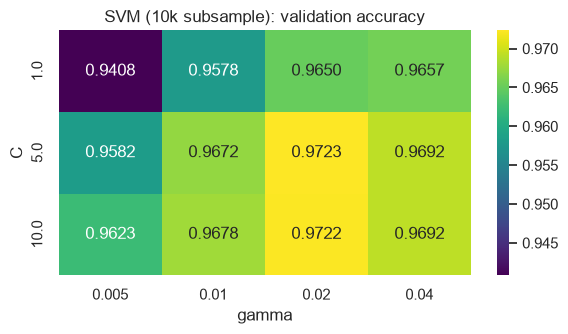

Selected SVM hyper-parameters: {'kernel': 'rbf', 'C': 5.0, 'gamma': 0.02} | val acc on subsample 0.9723


In [7]:
grid = svm_df[svm_df.stage == "2 rbf grid"].pivot(index="C", columns="gamma", values="val_acc")
plt.figure(figsize=(6, 3.5)); sns.heatmap(grid, annot=True, fmt=".4f", cmap="viridis"); plt.title("SVM (10k subsample): validation accuracy")
plt.tight_layout(); plt.savefig(ARTIFACTS / "svm_grid.png", dpi=120); plt.show()
best_row = svm_df[svm_df.stage == "2 rbf grid"].sort_values("val_acc", ascending=False).iloc[0]
SVM_PARAMS = dict(kernel="rbf", C=float(best_row.C), gamma=float(best_row.gamma))
print("Selected SVM hyper-parameters:", SVM_PARAMS, "| val acc on subsample %.4f" % best_row.val_acc)

**Reading the search:** the linear kernel is clearly worse than the non-linear kernels (digits are not linearly separable in pixel space), which confirms
the choice of RBF. In the grid, too small a `gamma` (0.005) under-fits and too large a `gamma` (0.04) makes each support vector too local; larger `C` helps until the
decision boundary is flexible enough. The selected values are the best cell of the validation grid (printed above). If the best cell lies on the edge of the grid,
that is noted as a limitation (the grid could be extended with more compute).

In [8]:
svm_final, svm_fit_time = fit_svm(SVM_PARAMS, X["flat"]["train"], y_tr)      # full 54,000-image training split
print("trained on", len(y_tr), "images in %.1f s | support vectors: %d" % (svm_fit_time, svm_final.n_support_.sum()))
tr_x, tr_y = X["flat"]["train"][sub_idx], y_tr[sub_idx]
evaluate_final("SVM", svm_final.predict, tr_x, tr_y, X["flat"]["val"], y_val, X["flat"]["test"], y_test, svm_fit_time,
               complexity=int(svm_final.support_vectors_.size), extra=dict(complexity_note="values stored in support vectors"))

trained on 54000 images in 151.3 s | support vectors: 12453


SVM: train 0.9999 | val 0.9842 | TEST 0.9851 | macro-F1 0.9850 | train time 151.3s | inference 6.693 ms/img
              precision    recall  f1-score   support

           0     0.9838    0.9939    0.9888       980
           1     0.9912    0.9956    0.9934      1135
           2     0.9826    0.9826    0.9826      1032
           3     0.9852    0.9881    0.9867      1010
           4     0.9868    0.9868    0.9868       982
           5     0.9876    0.9821    0.9848       892
           6     0.9895    0.9875    0.9885       958
           7     0.9824    0.9776    0.9800      1028
           8     0.9846    0.9825    0.9836       974
           9     0.9771    0.9732    0.9752      1009

    accuracy                         0.9851     10000
   macro avg     0.9851    0.9850    0.9850     10000
weighted avg     0.9851    0.9851    0.9851     10000



{'train_acc': 0.9999,
 'val_acc': 0.9841666666666666,
 'test_acc': 0.9851,
 'macro_precision': 0.9850804219131577,
 'macro_recall': 0.9849861104006253,
 'macro_f1': 0.9850280644517143,
 'train_time_s': 151.31733569999778,
 'inference_ms_per_image': 6.693210139999792,
 'complexity': 9763152,
 'test_errors': 149,
 'pred_test': array([7, 2, 1, ..., 4, 5, 6], shape=(10000,)),
 'complexity_note': 'values stored in support vectors'}

## 6. Model 2 - Multi-layer perceptron (fully connected layers only)
**Architecture:** `784 -> [Linear -> ReLU -> Dropout] x (hidden layers) -> Linear(10)` trained with cross-entropy (softmax) loss. No convolutional layers.
Flattening discards the 2-D structure, so the MLP must learn digit shapes from raw pixel positions.

**Hyper-parameters searched** (two stages, validation accuracy after a fixed 10-epoch budget, Adam optimiser):
* Stage 1 (full grid, 3x3x2 = 18 runs): hidden layout {(128,), (256,128), (512,256)} - capacity; learning rate {1e-2, 1e-3, 1e-4} - the most influential NN hyper-parameter; dropout {0.0, 0.3} - regularisation.
* Stage 2 (6 runs around the stage-1 winner): batch size {64, 128, 256} x weight decay {0, 1e-4}.
* The **baseline** is the plain configuration (128,), lr 1e-3, no dropout, batch 128 (part of the grid).
* Final model: trained for up to 30 epochs with the best configuration; the epoch with the best validation accuracy is kept (early stopping).

In [9]:
SEARCH_EPOCHS_MLP = 10
mlp_log = []
def try_mlp(stage, hidden, lr, dropout, batch, wd=0.0):
    m = MLP(hidden, dropout)
    _, h = train_torch(m, X["flat"]["train"], y_tr, X["flat"]["val"], y_val, lr=lr, batch_size=batch,
                       epochs=SEARCH_EPOCHS_MLP, weight_decay=wd, seed=SEED)
    mlp_log.append(dict(stage=stage, hidden=str(hidden), lr=lr, dropout=dropout, batch=batch, wd=wd,
                        val_acc=max(h["val_acc"]), final_train_acc=h["train_acc"][-1], train_s=h["train_time_s"], params=count_parameters(m)))
    print(mlp_log[-1])

for hidden in [(128,), (256, 128), (512, 256)]:
    for lr in [1e-2, 1e-3, 1e-4]:
        for dropout in [0.0, 0.3]:
            try_mlp("1", hidden, lr, dropout, 128)
mlp1 = pd.DataFrame(mlp_log)

{'stage': '1', 'hidden': '(128,)', 'lr': 0.01, 'dropout': 0.0, 'batch': 128, 'wd': 0.0, 'val_acc': 0.9705, 'final_train_acc': 0.9871851851851852, 'train_s': 20.604265799996938, 'params': 101770}


{'stage': '1', 'hidden': '(128,)', 'lr': 0.01, 'dropout': 0.3, 'batch': 128, 'wd': 0.0, 'val_acc': 0.969, 'final_train_acc': 0.9630185185185185, 'train_s': 5.566570400002092, 'params': 101770}


{'stage': '1', 'hidden': '(128,)', 'lr': 0.001, 'dropout': 0.0, 'batch': 128, 'wd': 0.0, 'val_acc': 0.9758333333333333, 'final_train_acc': 0.9891296296296296, 'train_s': 4.499567399998341, 'params': 101770}


{'stage': '1', 'hidden': '(128,)', 'lr': 0.001, 'dropout': 0.3, 'batch': 128, 'wd': 0.0, 'val_acc': 0.9753333333333334, 'final_train_acc': 0.9766666666666667, 'train_s': 4.624235400002362, 'params': 101770}


{'stage': '1', 'hidden': '(128,)', 'lr': 0.0001, 'dropout': 0.0, 'batch': 128, 'wd': 0.0, 'val_acc': 0.9326666666666666, 'final_train_acc': 0.9355, 'train_s': 4.5273973000003025, 'params': 101770}


...

{'stage': '1', 'hidden': '(512, 256)', 'lr': 0.01, 'dropout': 0.3, 'batch': 128, 'wd': 0.0, 'val_acc': 0.9655, 'final_train_acc': 0.9505370370370371, 'train_s': 5.827379600003042, 'params': 535818}


{'stage': '1', 'hidden': '(512, 256)', 'lr': 0.001, 'dropout': 0.0, 'batch': 128, 'wd': 0.0, 'val_acc': 0.9795, 'final_train_acc': 0.9949259259259259, 'train_s': 5.316779900000256, 'params': 535818}


{'stage': '1', 'hidden': '(512, 256)', 'lr': 0.001, 'dropout': 0.3, 'batch': 128, 'wd': 0.0, 'val_acc': 0.978, 'final_train_acc': 0.9880185185185185, 'train_s': 5.864023800000723, 'params': 535818}


{'stage': '1', 'hidden': '(512, 256)', 'lr': 0.0001, 'dropout': 0.0, 'batch': 128, 'wd': 0.0, 'val_acc': 0.9658333333333333, 'final_train_acc': 0.9724814814814815, 'train_s': 5.2238323999990826, 'params': 535818}


{'stage': '1', 'hidden': '(512, 256)', 'lr': 0.0001, 'dropout': 0.3, 'batch': 128, 'wd': 0.0, 'val_acc': 0.9656666666666667, 'final_train_acc': 0.9641296296296297, 'train_s': 5.531125699999393, 'params': 535818}


In [10]:
best1 = mlp1.sort_values("val_acc", ascending=False).iloc[0]
hid_best = eval(best1.hidden)
print("stage-1 winner:", dict(best1))
for batch in [64, 128, 256]:
    for wd in [0.0, 1e-4]:
        if batch == 128 and wd == 0.0: continue          # already run in stage 1
        try_mlp("2", hid_best, best1.lr, best1.dropout, batch, wd)
mlp_df = pd.DataFrame(mlp_log); mlp_df.to_csv(ARTIFACTS / "mlp_search.csv", index=False)
display(mlp_df.sort_values("val_acc", ascending=False).head(10))

stage-1 winner: {'stage': '1', 'hidden': '(256, 128)', 'lr': np.float64(0.001), 'dropout': np.float64(0.3), 'batch': np.int64(128), 'wd': np.float64(0.0), 'val_acc': np.float64(0.9803333333333333), 'final_train_acc': np.float64(0.9832037037037037), 'train_s': np.float64(5.6787561000019195), 'params': np.int64(235146)}


{'stage': '2', 'hidden': '(256, 128)', 'lr': np.float64(0.001), 'dropout': np.float64(0.3), 'batch': 64, 'wd': 0.0, 'val_acc': 0.9821666666666666, 'final_train_acc': 0.9832222222222222, 'train_s': 11.722253899999487, 'params': 235146}


{'stage': '2', 'hidden': '(256, 128)', 'lr': np.float64(0.001), 'dropout': np.float64(0.3), 'batch': 64, 'wd': 0.0001, 'val_acc': 0.9811666666666666, 'final_train_acc': 0.9798703703703704, 'train_s': 12.360515399999713, 'params': 235146}


{'stage': '2', 'hidden': '(256, 128)', 'lr': np.float64(0.001), 'dropout': np.float64(0.3), 'batch': 128, 'wd': 0.0001, 'val_acc': 0.9785, 'final_train_acc': 0.9802037037037037, 'train_s': 6.087169900001754, 'params': 235146}


{'stage': '2', 'hidden': '(256, 128)', 'lr': np.float64(0.001), 'dropout': np.float64(0.3), 'batch': 256, 'wd': 0.0, 'val_acc': 0.9781666666666666, 'final_train_acc': 0.9808148148148148, 'train_s': 2.8837027000008675, 'params': 235146}


{'stage': '2', 'hidden': '(256, 128)', 'lr': np.float64(0.001), 'dropout': np.float64(0.3), 'batch': 256, 'wd': 0.0001, 'val_acc': 0.9786666666666667, 'final_train_acc': 0.9801666666666666, 'train_s': 3.0069183000014164, 'params': 235146}


,stage,hidden,lr,dropout,batch,wd,val_acc,final_train_acc,train_s,params
18,2,"(256, 128)",0.001,0.3,64,0.0000,0.982167,0.983222,11.722254,235146
19,2,"(256, 128)",0.001,0.3,64,0.0001,0.981167,0.979870,12.360515,235146
9,1,"(256, 128)",0.001,0.3,128,0.0000,0.980333,0.983204,5.678756,235146
14,1,"(512, 256)",0.001,0.0,128,0.0000,0.979500,0.994926,5.316780,535818
22,2,"(256, 128)",0.001,0.3,256,0.0001,0.978667,0.980167,3.006918,235146
20,2,"(256, 128)",0.001,0.3,128,0.0001,0.978500,0.980204,6.087170,235146
21,2,"(256, 128)",0.001,0.3,256,0.0000,0.978167,0.980815,2.883703,235146
15,1,"(512, 256)",0.001,0.3,128,0.0000,0.978000,0.988019,5.864024,535818
8,1,"(256, 128)",0.001,0.0,128,0.0000,0.976167,0.995185,5.300355,235146
2,1,"(128,)",0.001,0.0,128,0.0000,0.975833,0.989130,4.499567,101770


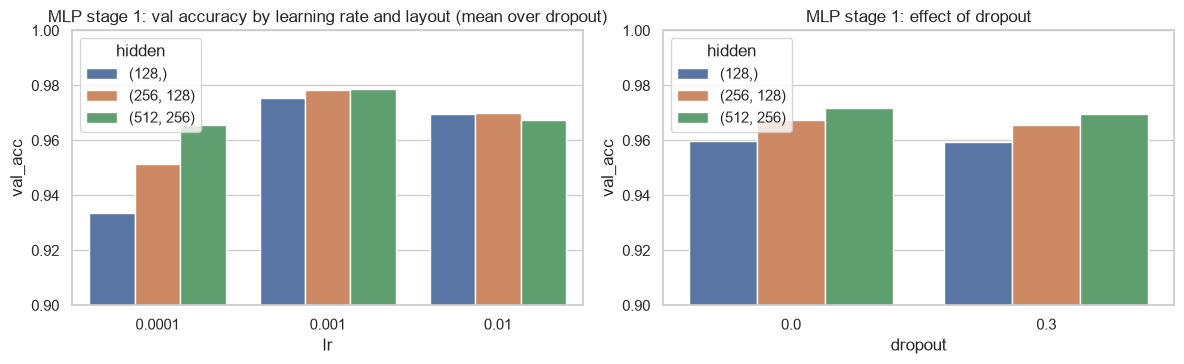

Selected MLP configuration: {'hidden': (256, 128), 'lr': 0.001, 'dropout': 0.3, 'batch': 64, 'wd': 0.0} | val acc (10 epochs) 0.9822


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
s1 = mlp_df[mlp_df.stage == "1"]
sns.barplot(data=s1, x="lr", y="val_acc", hue="hidden", errorbar=None, ax=ax[0]); ax[0].set_ylim(0.9, 1.0)
ax[0].set_title("MLP stage 1: val accuracy by learning rate and layout (mean over dropout)")
sns.barplot(data=s1, x="dropout", y="val_acc", hue="hidden", errorbar=None, ax=ax[1]); ax[1].set_ylim(0.9, 1.0)
ax[1].set_title("MLP stage 1: effect of dropout")
plt.tight_layout(); plt.savefig(ARTIFACTS / "mlp_search.png", dpi=120); plt.show()
bm = mlp_df.sort_values("val_acc", ascending=False).iloc[0]
MLP_CFG = dict(hidden=eval(bm.hidden), lr=float(bm.lr), dropout=float(bm.dropout), batch=int(bm.batch), wd=float(bm.wd))
print("Selected MLP configuration:", MLP_CFG, "| val acc (10 epochs) %.4f" % bm.val_acc)

**Reading the search:** the learning rate has the largest effect - 1e-4 is too slow to converge in 10 epochs and 1e-2 is unstable for the Adam optimiser, while 1e-3 works well.
Wider/deeper layouts help up to a point, and dropout/weight-decay trade a little training accuracy for better validation accuracy. The exact winner is printed above and used for the final run.

In [12]:
mlp_final, mlp_hist = train_torch(MLP(MLP_CFG["hidden"], MLP_CFG["dropout"]), X["flat"]["train"], y_tr, X["flat"]["val"], y_val,
                                  lr=MLP_CFG["lr"], batch_size=MLP_CFG["batch"], epochs=30, weight_decay=MLP_CFG["wd"],
                                  seed=SEED, restore_best=True, verbose=False)
print("best epoch:", mlp_hist["best_epoch"], "of 30 | total training time %.1f s (all 30 epochs)" % mlp_hist["train_time_s"])
mlp_time_to_best = mlp_hist["train_time_s"] * mlp_hist["best_epoch"] / 30
mlp_pred = lambda x: predict_proba(mlp_final, torch.from_numpy(x)).argmax(1)
evaluate_final("MLP", mlp_pred, X["flat"]["train"][sub_idx], y_tr[sub_idx], X["flat"]["val"], y_val, X["flat"]["test"], y_test,
               mlp_hist["train_time_s"], complexity=count_parameters(mlp_final), extra=dict(best_epoch=mlp_hist["best_epoch"]))
FINAL["MLP"]["train_time_to_best_epoch_s"] = mlp_time_to_best

best epoch: 26 of 30 | total training time 42.5 s (all 30 epochs)
MLP: train 0.9984 | val 0.9837 | TEST 0.9813 | macro-F1 0.9812 | train time 42.5s | inference 0.001 ms/img
              precision    recall  f1-score   support

           0     0.9808    0.9929    0.9868       980
           1     0.9912    0.9903    0.9907      1135
           2     0.9816    0.9806    0.9811      1032
           3     0.9736    0.9861    0.9798      1010
           4     0.9826    0.9776    0.9801       982
           5     0.9864    0.9753    0.9808       892
           6     0.9884    0.9802    0.9843       958
           7     0.9721    0.9825    0.9773      1028
           8     0.9782    0.9692    0.9737       974
           9     0.9782    0.9762    0.9772      1009

    accuracy                         0.9813     10000
   macro avg     0.9813    0.9811    0.9812     10000
weighted avg     0.9813    0.9813    0.9813     10000



## 7. Model 3 - Simple CNN
**Architecture** (the standard introductory design, only 4 weight layers, no pre-training):

`Input 1x28x28 -> Conv3x3(f1)+ReLU -> MaxPool2 -> Conv3x3(f2)+ReLU -> MaxPool2 -> Flatten -> Linear(64)+ReLU -> Dropout -> Linear(10)`

Convolutions share weights across the image and capture local strokes/edges regardless of where they appear, which is why CNNs suit images better than an MLP.

**Hyper-parameters searched** (validation accuracy after a fixed 6-epoch budget, Adam):
* Stage 1 (full grid, 3x3x2 = 18 runs): number of filters (f1,f2) {(8,16), (16,32), (32,64)} - capacity; learning rate {3e-3, 1e-3, 3e-4}; dropout {0.0, 0.4}.
* Stage 2 (5 runs around the stage-1 winner): batch size {64, 128, 256} x weight decay {0, 1e-4}.
* **Baseline:** (16,32) filters, lr 1e-3, no dropout, batch 128 (part of the grid).
* Fixed choices (not tuned, to keep the search small): 3x3 kernels with padding 1, 2x2 max-pooling, 64 units in the dense layer, Adam optimiser.
* Final model: up to 15 epochs, best-validation epoch kept.

In [13]:
SEARCH_EPOCHS_CNN = 6
cnn_log = []
def try_cnn(stage, filters, lr, dropout, batch, wd=0.0):
    m = SimpleCNN(filters, 64, dropout)
    _, h = train_torch(m, X["img"]["train"], y_tr, X["img"]["val"], y_val, lr=lr, batch_size=batch,
                       epochs=SEARCH_EPOCHS_CNN, weight_decay=wd, seed=SEED)
    cnn_log.append(dict(stage=stage, filters=str(filters), lr=lr, dropout=dropout, batch=batch, wd=wd,
                        val_acc=max(h["val_acc"]), final_train_acc=h["train_acc"][-1], train_s=h["train_time_s"], params=count_parameters(m)))
    print(cnn_log[-1])

for filters in [(8, 16), (16, 32), (32, 64)]:
    for lr in [3e-3, 1e-3, 3e-4]:
        for dropout in [0.0, 0.4]:
            try_cnn("1", filters, lr, dropout, 128)
cnn1 = pd.DataFrame(cnn_log)

{'stage': '1', 'filters': '(8, 16)', 'lr': 0.003, 'dropout': 0.0, 'batch': 128, 'wd': 0.0, 'val_acc': 0.9836666666666667, 'final_train_acc': 0.9910185185185185, 'train_s': 4.679265099999611, 'params': 52138}


{'stage': '1', 'filters': '(8, 16)', 'lr': 0.003, 'dropout': 0.4, 'batch': 128, 'wd': 0.0, 'val_acc': 0.9828333333333333, 'final_train_acc': 0.9725370370370371, 'train_s': 4.395459499999561, 'params': 52138}


{'stage': '1', 'filters': '(8, 16)', 'lr': 0.001, 'dropout': 0.0, 'batch': 128, 'wd': 0.0, 'val_acc': 0.982, 'final_train_acc': 0.9853518518518518, 'train_s': 4.218847799998912, 'params': 52138}


{'stage': '1', 'filters': '(8, 16)', 'lr': 0.001, 'dropout': 0.4, 'batch': 128, 'wd': 0.0, 'val_acc': 0.9801666666666666, 'final_train_acc': 0.9666111111111111, 'train_s': 5.092130699998961, 'params': 52138}


{'stage': '1', 'filters': '(8, 16)', 'lr': 0.0003, 'dropout': 0.0, 'batch': 128, 'wd': 0.0, 'val_acc': 0.9671666666666666, 'final_train_acc': 0.9700555555555556, 'train_s': 5.867035399998713, 'params': 52138}


...

{'stage': '1', 'filters': '(32, 64)', 'lr': 0.003, 'dropout': 0.4, 'batch': 128, 'wd': 0.0, 'val_acc': 0.9876666666666667, 'final_train_acc': 0.9822407407407407, 'train_s': 6.34758729999885, 'params': 220234}


{'stage': '1', 'filters': '(32, 64)', 'lr': 0.001, 'dropout': 0.0, 'batch': 128, 'wd': 0.0, 'val_acc': 0.9863333333333333, 'final_train_acc': 0.9925185185185185, 'train_s': 5.884848200003034, 'params': 220234}


{'stage': '1', 'filters': '(32, 64)', 'lr': 0.001, 'dropout': 0.4, 'batch': 128, 'wd': 0.0, 'val_acc': 0.9866666666666667, 'final_train_acc': 0.9788703703703704, 'train_s': 6.2015025000000605, 'params': 220234}


{'stage': '1', 'filters': '(32, 64)', 'lr': 0.0003, 'dropout': 0.0, 'batch': 128, 'wd': 0.0, 'val_acc': 0.9826666666666667, 'final_train_acc': 0.9852222222222222, 'train_s': 6.194734099997731, 'params': 220234}


{'stage': '1', 'filters': '(32, 64)', 'lr': 0.0003, 'dropout': 0.4, 'batch': 128, 'wd': 0.0, 'val_acc': 0.9821666666666666, 'final_train_acc': 0.9702222222222222, 'train_s': 6.362719100001414, 'params': 220234}


In [14]:
best1 = cnn1.sort_values("val_acc", ascending=False).iloc[0]
filt_best = eval(best1.filters)
print("stage-1 winner:", dict(best1))
for batch in [64, 128, 256]:
    for wd in [0.0, 1e-4]:
        if batch == 128 and wd == 0.0: continue
        try_cnn("2", filt_best, best1.lr, best1.dropout, batch, wd)
cnn_df = pd.DataFrame(cnn_log); cnn_df.to_csv(ARTIFACTS / "cnn_search.csv", index=False)
display(cnn_df.sort_values("val_acc", ascending=False).head(10))

stage-1 winner: {'stage': '1', 'filters': '(32, 64)', 'lr': np.float64(0.003), 'dropout': np.float64(0.0), 'batch': np.int64(128), 'wd': np.float64(0.0), 'val_acc': np.float64(0.9886666666666667), 'final_train_acc': np.float64(0.9947777777777778), 'train_s': np.float64(6.134394799999427), 'params': np.int64(220234)}


{'stage': '2', 'filters': '(32, 64)', 'lr': np.float64(0.003), 'dropout': np.float64(0.0), 'batch': 64, 'wd': 0.0, 'val_acc': 0.9893333333333333, 'final_train_acc': 0.994462962962963, 'train_s': 11.885962799999106, 'params': 220234}


{'stage': '2', 'filters': '(32, 64)', 'lr': np.float64(0.003), 'dropout': np.float64(0.0), 'batch': 64, 'wd': 0.0001, 'val_acc': 0.9891666666666666, 'final_train_acc': 0.9917222222222222, 'train_s': 12.321472200001153, 'params': 220234}


{'stage': '2', 'filters': '(32, 64)', 'lr': np.float64(0.003), 'dropout': np.float64(0.0), 'batch': 128, 'wd': 0.0001, 'val_acc': 0.9895, 'final_train_acc': 0.9928148148148148, 'train_s': 6.326808800000435, 'params': 220234}


{'stage': '2', 'filters': '(32, 64)', 'lr': np.float64(0.003), 'dropout': np.float64(0.0), 'batch': 256, 'wd': 0.0, 'val_acc': 0.9873333333333333, 'final_train_acc': 0.9937777777777778, 'train_s': 3.766291200001433, 'params': 220234}


{'stage': '2', 'filters': '(32, 64)', 'lr': np.float64(0.003), 'dropout': np.float64(0.0), 'batch': 256, 'wd': 0.0001, 'val_acc': 0.9876666666666667, 'final_train_acc': 0.9931111111111111, 'train_s': 3.5493634000013117, 'params': 220234}


,stage,filters,lr,dropout,batch,wd,val_acc,final_train_acc,train_s,params
20,2,"(32, 64)",0.003,0.0,128,0.0001,0.989500,0.992815,6.326809,220234
18,2,"(32, 64)",0.003,0.0,64,0.0000,0.989333,0.994463,11.885963,220234
19,2,"(32, 64)",0.003,0.0,64,0.0001,0.989167,0.991722,12.321472,220234
12,1,"(32, 64)",0.003,0.0,128,0.0000,0.988667,0.994778,6.134395,220234
6,1,"(16, 32)",0.003,0.0,128,0.0000,0.988500,0.993759,6.675164,105866
13,1,"(32, 64)",0.003,0.4,128,0.0000,0.987667,0.982241,6.347587,220234
22,2,"(32, 64)",0.003,0.0,256,0.0001,0.987667,0.993111,3.549363,220234
21,2,"(32, 64)",0.003,0.0,256,0.0000,0.987333,0.993778,3.766291,220234
15,1,"(32, 64)",0.001,0.4,128,0.0000,0.986667,0.978870,6.201503,220234
14,1,"(32, 64)",0.001,0.0,128,0.0000,0.986333,0.992519,5.884848,220234


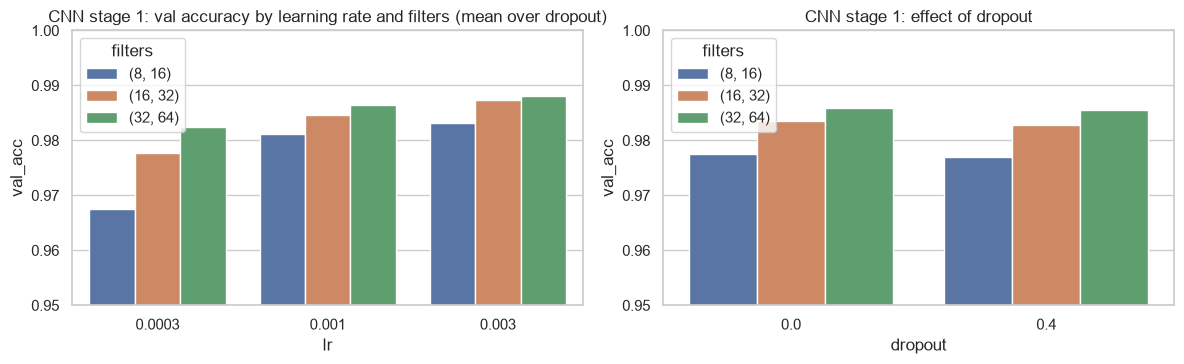

Selected CNN configuration: {'filters': (32, 64), 'lr': 0.003, 'dropout': 0.0, 'batch': 128, 'wd': 0.0001} | val acc (6 epochs) 0.9895


In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
s1 = cnn_df[cnn_df.stage == "1"]
sns.barplot(data=s1, x="lr", y="val_acc", hue="filters", errorbar=None, ax=ax[0]); ax[0].set_ylim(0.95, 1.0)
ax[0].set_title("CNN stage 1: val accuracy by learning rate and filters (mean over dropout)")
sns.barplot(data=s1, x="dropout", y="val_acc", hue="filters", errorbar=None, ax=ax[1]); ax[1].set_ylim(0.95, 1.0)
ax[1].set_title("CNN stage 1: effect of dropout")
plt.tight_layout(); plt.savefig(ARTIFACTS / "cnn_search.png", dpi=120); plt.show()
bm = cnn_df.sort_values("val_acc", ascending=False).iloc[0]
CNN_CFG = dict(filters=eval(bm.filters), lr=float(bm.lr), dropout=float(bm.dropout), batch=int(bm.batch), wd=float(bm.wd))
print("Selected CNN configuration:", CNN_CFG, "| val acc (6 epochs) %.4f" % bm.val_acc)

**Reading the search:** the CNN is much less sensitive to the hyper-parameters than the MLP (almost every configuration exceeds 98 % validation accuracy after 6 epochs); the learning rate and the
number of filters matter most, and dropout/weight decay mainly reduce the train-validation gap. The final configuration is printed above.

In [16]:
cnn_final, cnn_hist = train_torch(SimpleCNN(CNN_CFG["filters"], 64, CNN_CFG["dropout"]), X["img"]["train"], y_tr, X["img"]["val"], y_val,
                                  lr=CNN_CFG["lr"], batch_size=CNN_CFG["batch"], epochs=15, weight_decay=CNN_CFG["wd"],
                                  seed=SEED, restore_best=True)
print("best epoch:", cnn_hist["best_epoch"], "of 15 | total training time %.1f s (all 15 epochs)" % cnn_hist["train_time_s"])
cnn_pred = lambda x: predict_proba(cnn_final, torch.from_numpy(x)).argmax(1)
evaluate_final("CNN", cnn_pred, X["img"]["train"][sub_idx], y_tr[sub_idx], X["img"]["val"], y_val, X["img"]["test"], y_test,
               cnn_hist["train_time_s"], complexity=count_parameters(cnn_final), extra=dict(best_epoch=cnn_hist["best_epoch"]))
FINAL["CNN"]["train_time_to_best_epoch_s"] = cnn_hist["train_time_s"] * cnn_hist["best_epoch"] / 15

best epoch: 13 of 15 | total training time 15.6 s (all 15 epochs)
CNN: train 0.9977 | val 0.9892 | TEST 0.9907 | macro-F1 0.9906 | train time 15.6s | inference 0.004 ms/img
              precision    recall  f1-score   support

           0     0.9849    0.9969    0.9909       980
           1     0.9921    0.9965    0.9943      1135
           2     0.9913    0.9942    0.9927      1032
           3     0.9941    0.9960    0.9951      1010
           4     0.9919    0.9959    0.9939       982
           5     0.9866    0.9888    0.9877       892
           6     0.9937    0.9812    0.9874       958
           7     0.9893    0.9864    0.9878      1028
           8     0.9898    0.9918    0.9908       974
           9     0.9930    0.9782    0.9855      1009

    accuracy                         0.9907     10000
   macro avg     0.9906    0.9906    0.9906     10000
weighted avg     0.9907    0.9907    0.9907     10000



## 8. Saving the three final models
* **SVM** - `models/classical_svm.joblib` (scikit-learn's standard persistence format, `joblib`, compressed).
* **MLP / CNN** - `models/mlp_model.pt`, `models/cnn_model.pt`: PyTorch's standard `torch.save` of a dictionary containing the `state_dict` (weights), the architecture name and the constructor arguments, so
  that `src/inference.py` can rebuild the identical network (`MLP` / `SimpleCNN` classes in `src/model_utils.py`) and load the weights (`weights_only=True`, safe loading).

In [17]:
joblib.dump(svm_final, MODELS / "classical_svm.joblib", compress=3)
torch.save(dict(arch="mlp", config=dict(hidden_sizes=tuple(MLP_CFG["hidden"]), dropout=MLP_CFG["dropout"]), state_dict=mlp_final.state_dict(),
                input="flattened 784 floats in [0,1]"), MODELS / "mlp_model.pt")
torch.save(dict(arch="cnn", config=dict(filters=tuple(CNN_CFG["filters"]), fc_units=64, dropout=CNN_CFG["dropout"]), state_dict=cnn_final.state_dict(),
                input="(1,28,28) floats in [0,1]"), MODELS / "cnn_model.pt")
for f in sorted(MODELS.iterdir()):
    print(f"{f.name:22s} {f.stat().st_size / 1e6:8.2f} MB")
    FINAL[{"classical_svm.joblib": "SVM", "mlp_model.pt": "MLP", "cnn_model.pt": "CNN"}[f.name]]["file_mb"] = f.stat().st_size / 1e6

FINAL["SVM"]["best_epoch"] = None
histories = dict(MLP=mlp_hist, CNN=cnn_hist)
(ARTIFACTS / "training_histories.json").write_text(json.dumps(histories, indent=2))
summary = {n: {k: (float(v) if isinstance(v, (np.floating, float)) else v) for k, v in FINAL[n].items() if k != "pred_test"} for n in FINAL}
summary["hyperparameters"] = dict(SVM=SVM_PARAMS, MLP={k: (list(v) if isinstance(v, tuple) else v) for k, v in MLP_CFG.items()},
                                  CNN={k: (list(v) if isinstance(v, tuple) else v) for k, v in CNN_CFG.items()})
(ARTIFACTS / "final_results.json").write_text(json.dumps(summary, indent=2, default=int))
print("stored results, training histories and search tables in", ARTIFACTS.resolve())

classical_svm.joblib       5.83 MB
cnn_model.pt               0.89 MB
mlp_model.pt               0.94 MB
stored results, training histories and search tables in E:\trainingproject 1\artifacts


## 9. Smoke tests: load the saved files and run inference exactly as the app does
1. Load all three models from disk with `inference.DigitRecognizer` (a fresh load, independent of the objects trained above).
2. Check that the saved models reproduce the test predictions made above.
3. Push a *simulated hand drawing* (a test digit enlarged onto a 280x280 canvas with thick strokes) through the app's `canvas_to_mnist` pipeline into each model.

loaded: {'svm': 'SVC', 'mlp': 'MLP', 'cnn': 'SimpleCNN'}


SVM: reloaded model agrees with trained model on 99.9% of 1000 test images


MLP: reloaded model agrees with trained model on 100.0% of 1000 test images


CNN: reloaded model agrees with trained model on 100.0% of 1000 test images


{'svm': '98.5%', 'mlp': '97.5%', 'cnn': '97.5%'} correct on 200 simulated drawings (canvas pipeline check)


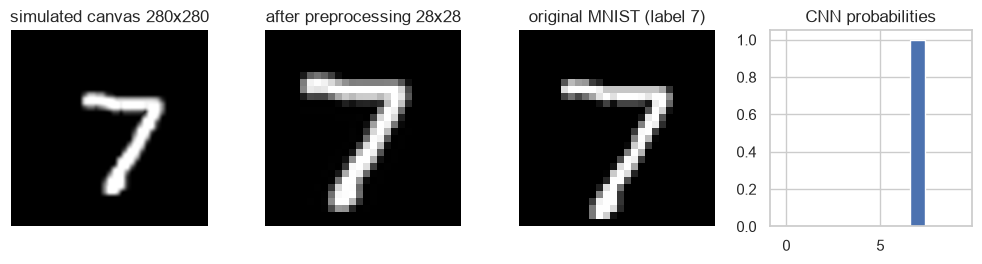

In [18]:
import importlib, inference; importlib.reload(inference)
from PIL import Image, ImageFilter
rec = inference.DigitRecognizer()
print("loaded:", {k: type(v).__name__ for k, v in rec.models.items()})

# (2) saved models reproduce the in-memory predictions on 1000 test images
n = 1000
for key, name, view in [("svm", "SVM", "flat"), ("mlp", "MLP", "flat"), ("cnn", "CNN", "img")]:
    reloaded = np.array([rec.predict(key, x_test[i])[0] for i in range(n)])
    print(f"{name}: reloaded model agrees with trained model on {np.mean(reloaded == FINAL[name]['pred_test'][:n]):.1%} of {n} test images")

# (3) simulated drawing -> canvas -> app preprocessing -> every model
def fake_drawing(img28):
    big = Image.fromarray((img28 * 255).astype(np.uint8)).resize((200, 200), Image.BICUBIC)   # digit drawn at 200px
    canvas = Image.new("L", (280, 280), 0); canvas.paste(big, (60, 40))                      # off-centre like a user's drawing
    return canvas.filter(ImageFilter.MaxFilter(5))                                           # thicker pen stroke
ok = {k: 0 for k in rec.models}; N = 200
for i in range(N):
    arr = inference.canvas_to_mnist(fake_drawing(x_test[i]))
    for k in rec.models: ok[k] += rec.predict(k, arr)[0] == y_test[i]
print({k: f"{v / N:.1%}" for k, v in ok.items()}, f"correct on {N} simulated drawings (canvas pipeline check)")

fig, axes = plt.subplots(1, 4, figsize=(10, 2.8))
canvas_img = fake_drawing(x_test[0]); axes[0].imshow(canvas_img, cmap="gray"); axes[0].set_title("simulated canvas 280x280")
axes[1].imshow(inference.canvas_to_mnist(canvas_img), cmap="gray"); axes[1].set_title("after preprocessing 28x28")
axes[2].imshow(x_test[0], cmap="gray"); axes[2].set_title(f"original MNIST (label {y_test[0]})")
axes[3].bar(range(10), rec.predict("cnn", inference.canvas_to_mnist(canvas_img))[1]); axes[3].set_title("CNN probabilities")
for a in axes[:3]: a.axis("off")
plt.tight_layout(); plt.show()